# 02 · Analysis: how much do blood pressure and cholesterol add beyond age?
Model A = age only. Model B = age + systolic + diastolic + cholesterol category. Logistic regression, 80/20 split, AUC overall and by age group, with a paired bootstrap for the gains. Executed notebook: outputs below are real fitted results.

In [1]:
# Setup: run this cell first (works locally and in Google Colab).
import sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
PUBLIC_REPO = "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git"
RAW_NAME = "cardiovascular_dataset_OpenBio_Final.csv"
def find_raw():
    here = Path.cwd().resolve()
    for f in [here, *here.parents]:
        for p in (f/"track-02"/"data"/RAW_NAME, f/"data"/RAW_NAME, f/RAW_NAME):
            if p.is_file(): return p
    if "google.colab" in sys.modules:
        dest = Path("/content/openbio-datathon-2026")
        if not dest.exists(): subprocess.run(["git","clone","--depth","1",PUBLIC_REPO,str(dest)],check=True)
        return dest/"track-02"/"data"/RAW_NAME
    raise FileNotFoundError(RAW_NAME)
RAW = find_raw(); print("Raw data:", RAW)


Raw data: /home/claude/art/track-02/data/cardiovascular_dataset_OpenBio_Final.csv


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
raw = pd.read_csv(RAW, sep=";").drop_duplicates(subset="id")
df = raw[raw.gender==1].copy(); df["age_years"]=df.age/365.25
df = df[df.ap_hi.between(70,250)&df.ap_lo.between(40,150)&(df.ap_hi>df.ap_lo)].reset_index(drop=True)
LABELS=["Under 45","45 to 54","55 and older"]
df["age_group"]=pd.cut(df.age_years,[0,45,55,np.inf],labels=LABELS,right=False)
print(f"{len(df):,} women; {df.cardio.mean():.1%} labeled CVD")

44,727 women; 49.2% labeled CVD


In [3]:
# Same split as the team's working notebook: 20% held out, seed 42, stratified on age group x label
SEED, N_BOOT = 42, 2000
XA = df[["age_years"]]
XB = pd.get_dummies(df[["age_years","ap_hi","ap_lo","cholesterol"]], columns=["cholesterol"], drop_first=True).astype(float)
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=df.age_group.astype(str)+'_'+df.cardio.astype(str))
y = df.cardio
mA = LogisticRegression(C=1e6, max_iter=5000).fit(XA.loc[train_idx], y.loc[train_idx])
mB = LogisticRegression(C=1e6, max_iter=5000).fit(XB.loc[train_idx], y.loc[train_idx])
test = df.loc[test_idx].copy()
test["pA"] = mA.predict_proba(XA.loc[test_idx])[:,1]
test["pB"] = mB.predict_proba(XB.loc[test_idx])[:,1]
print("Held-out records:", len(test), test.age_group.value_counts().reindex(LABELS).to_dict())

Held-out records: 8946 {'Under 45': 1253, '45 to 54': 3655, '55 and older': 4038}


In [4]:
def auc_by_age(t):
    rows=[]
    for g in LABELS+["All women"]:
        s = t if g=="All women" else t[t.age_group==g]
        a, b = roc_auc_score(s.cardio,s.pA), roc_auc_score(s.cardio,s.pB)
        rows.append((g,len(s),a,b,b-a))
    return pd.DataFrame(rows,columns=["group","n_test","auc_age_only","auc_expanded","gain"])
res = auc_by_age(test); res.round(3)

,group,n_test,auc_age_only,auc_expanded,gain
0,Under 45,1253,0.585,0.835,0.251
1,45 to 54,3655,0.549,0.786,0.236
2,55 and older,4038,0.575,0.728,0.153
3,All women,8946,0.648,0.794,0.146


In [5]:
# Paired stratified bootstrap (2,000 resamples) for each gain and for the between-group contrasts
rng = np.random.default_rng(SEED)
pos = {g:(test[test.age_group==g].reset_index(drop=True)) for g in LABELS}
boot = {g:[] for g in LABELS}; bootA = {g:[] for g in LABELS}; bootB = {g:[] for g in LABELS}
for _ in range(N_BOOT):
    for g,s in pos.items():
        i = np.concatenate([rng.choice(np.where(s.cardio==k)[0], (s.cardio==k).sum()) for k in (0,1)])
        b = s.iloc[i]
        a_, b_ = roc_auc_score(b.cardio,b.pA), roc_auc_score(b.cardio,b.pB)
        bootA[g].append(a_); bootB[g].append(b_); boot[g].append(b_-a_)
boot = {g:np.array(v) for g,v in boot.items()}; bootA = {g:np.array(v) for g,v in bootA.items()}; bootB = {g:np.array(v) for g,v in bootB.items()}
ci = pd.DataFrame({g:np.percentile(v,[2.5,97.5]) for g,v in boot.items()}, index=["lo","hi"]).T.round(3)
ci.insert(0,"gain",res.set_index("group").loc[LABELS,"gain"].round(3)); ci

,gain,lo,hi
Under 45,0.251,0.211,0.293
45 to 54,0.236,0.215,0.258
55 and older,0.153,0.133,0.173


In [6]:
# Between-group contrasts (groups are disjoint, so resamples are independent)
con = {"Under 45 vs 55+": boot["Under 45"]-boot["55 and older"],
       "45 to 54 vs 55+": boot["45 to 54"]-boot["55 and older"],
       "Under 45 vs 45 to 54": boot["Under 45"]-boot["45 to 54"]}
g = res.set_index("group").gain
pt = {"Under 45 vs 55+":g["Under 45"]-g["55 and older"],"45 to 54 vs 55+":g["45 to 54"]-g["55 and older"],"Under 45 vs 45 to 54":g["Under 45"]-g["45 to 54"]}
pd.DataFrame({k:[round(pt[k],3),*np.percentile(v,[2.5,97.5]).round(3)] for k,v in con.items()},index=["diff","lo","hi"]).T

,diff,lo,hi
Under 45 vs 55+,0.098,0.053,0.146
45 to 54 vs 55+,0.084,0.054,0.114
Under 45 vs 45 to 54,0.014,-0.032,0.061


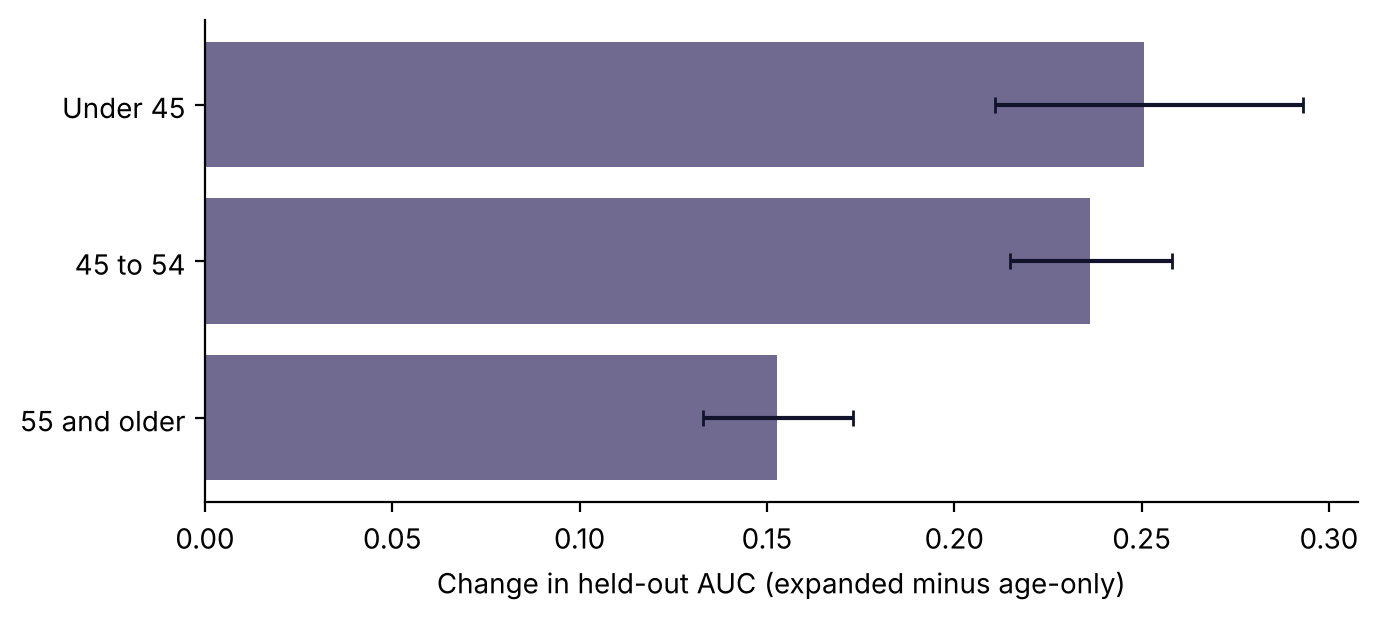

In [7]:
def plot_auc_gain(res, ci):
    fig, ax = plt.subplots(figsize=(7,3.2))
    r = res.set_index("group").loc[LABELS]
    ax.barh(LABELS[::-1], r.gain[::-1], color="#706a91")
    ax.errorbar(r.gain[::-1], range(3), xerr=[r.gain[::-1].values-ci.lo[::-1].values, ci.hi[::-1].values-r.gain[::-1].values], fmt="none", ecolor="#11132a", capsize=3)
    ax.set_xlabel("Change in held-out AUC (expanded minus age-only)"); ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout(); plt.show()
plot_auc_gain(res, ci)

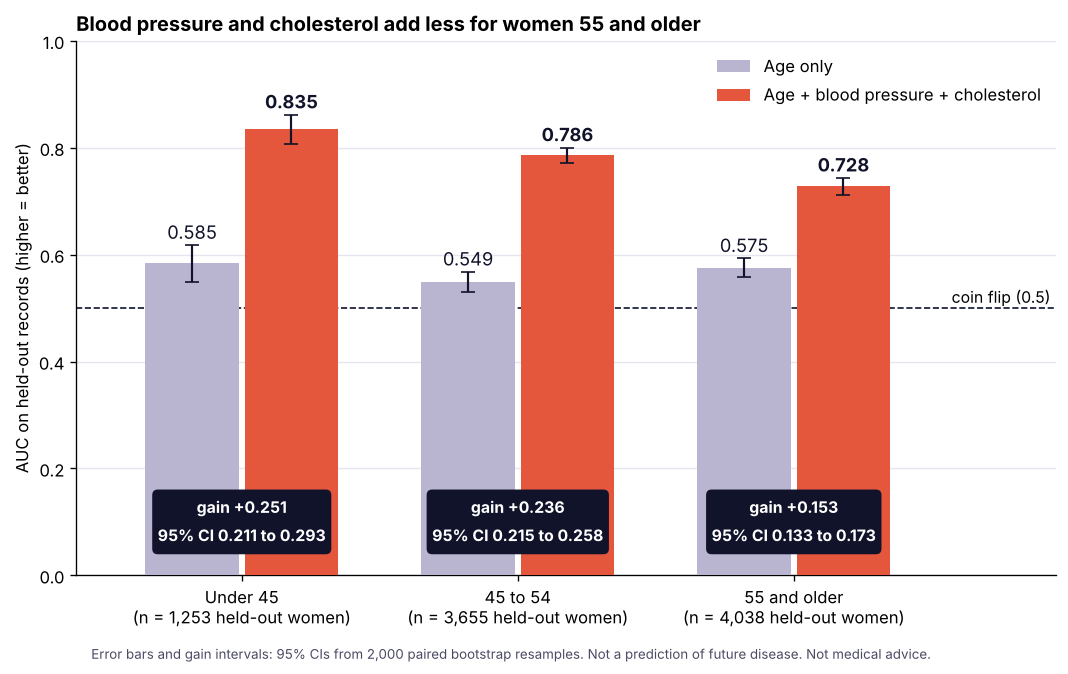

In [8]:
# Headline bar graph: AUC with 95% uncertainty bars, gain with its own interval
INK, LAV, CORAL = "#11132a", "#b9b5d1", "#e4573d"
r = res.set_index("group").loc[LABELS]
q = lambda d: np.array([np.percentile(d[g],[2.5,97.5]) for g in LABELS])
qa, qb, qg = q(bootA), q(bootB), q(boot)
fig, ax = plt.subplots(figsize=(9,5.6), dpi=120); x=np.arange(3); w=.36
for off, vals, ci_, col, lab in [(-w/2, r.auc_age_only.values, qa, LAV, "Age only"), (w/2, r.auc_expanded.values, qb, CORAL, "Age + blood pressure + cholesterol")]:
    ax.bar(x+off, vals, w*.94, color=col, label=lab, zorder=3)
    ax.errorbar(x+off, vals, yerr=[vals-ci_[:,0], ci_[:,1]-vals], fmt="none", ecolor=INK, capsize=4, lw=1.3, zorder=4)
    for xi, vi, h in zip(x+off, vals, ci_[:,1]): ax.text(xi, h+.012, f"{vi:.3f}", ha="center", fontsize=11, color=INK, fontweight="bold" if col==CORAL else "normal")
for xi, g_ in zip(x, LABELS):
    ax.text(xi, .10, f"gain +{r.gain[g_]:.3f}\n95% CI {qg[LABELS.index(g_),0]:.3f} to {qg[LABELS.index(g_),1]:.3f}", ha="center", va="center", linespacing=1.4, fontsize=9.5, color="white", fontweight="bold", zorder=5, bbox=dict(boxstyle="round,pad=0.35", fc=INK, ec="none"))
ax.axhline(.5, color=INK, ls="--", lw=1, zorder=2); ax.text(2.93, .51, "coin flip (0.5)", ha="right", fontsize=9.5)
ax.set_xlim(-.6, 2.95); ax.set_ylim(0,1); ax.set_xticks(x); ax.set_xticklabels([f"{g_}\n(n = {int(n):,} held-out women)" for g_,n in zip(LABELS, r.n_test)])
ax.set_ylabel("AUC on held-out records (higher = better)"); ax.grid(axis="y", color="#e6e4ee", zorder=0); ax.spines[["top","right"]].set_visible(False)
ax.legend(loc="upper right", frameon=False); ax.set_title("Blood pressure and cholesterol add less for women 55 and older", loc="left", fontweight="bold")
fig.text(.09, .01, "Error bars and gain intervals: 95% CIs from 2,000 paired bootstrap resamples. Not a prediction of future disease. Not medical advice.", fontsize=8, color="#4a4a63")
plt.tight_layout(rect=(0,.03,1,1)); plt.show()

In [9]:
# Split sensitivity: absolute AUCs move a little with the random split; the gains do not
rows=[]
for seed in [42,0,1,7,11,2026]:
    tr,te = train_test_split(df.index,test_size=.2,random_state=seed,stratify=df.age_group.astype(str)+'_'+df.cardio.astype(str))
    a=LogisticRegression(C=1e6,max_iter=5000).fit(XA.loc[tr],y.loc[tr]); b=LogisticRegression(C=1e6,max_iter=5000).fit(XB.loc[tr],y.loc[tr])
    t=df.loc[te].copy(); t["pA"]=a.predict_proba(XA.loc[te])[:,1]; t["pB"]=b.predict_proba(XB.loc[te])[:,1]
    r=auc_by_age(t).set_index("group")
    rows.append({"seed":seed, **{f"A {g}":round(r.auc_age_only[g],3) for g in LABELS}, **{f"B {g}":round(r.auc_expanded[g],3) for g in LABELS}, **{f"gain {g}":round(r.gain[g],3) for g in LABELS}})
pd.DataFrame(rows).set_index("seed")

,A Under 45,A 45 to 54,A 55 and older,B Under 45,B 45 to 54,B 55 and older,gain Under 45,gain 45 to 54,gain 55 and older
seed,,,,,,,,,
42,0.585,0.549,0.575,0.835,0.786,0.728,0.251,0.236,0.153
0,0.544,0.541,0.560,0.816,0.778,0.725,0.272,0.237,0.165
1,0.575,0.520,0.574,0.812,0.773,0.730,0.237,0.253,0.156
7,0.554,0.535,0.570,0.813,0.782,0.729,0.259,0.247,0.159
11,0.545,0.550,0.577,0.814,0.784,0.735,0.269,0.234,0.158
2026,0.577,0.527,0.580,0.821,0.782,0.725,0.245,0.255,0.145
